[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/10_coding_spectrum.ipynb)

# Coding spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the coding spectrum $\rho(\tau)$ of V1 and V4 against $\tau = \log t$ under the envelope spectrum of notebook 9, from stimulus–response pairs, and report $\tfrac12 \int \rho\, d\tau = I(R; X)$ for each area (task 4 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_coding_spectrum` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 7 min on a GPU.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 6.44 μs


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of this notebook (`figures/per_scale.py`, shared with notebooks 7 to 9), and set the parameters: the models, the test images, the noise levels, and where the figure goes.

<details><summary>Details</summary>

* `load_test_images` loads the test images; `compute_fisher_traces` gives the trace of the Fisher information J(x) of each image, from which the fine-end limit of the curve follows; `compute_information` integrates the curves, `compute_centre` says where they sit along log t, and `plot_coding_spectrum` draws the figure and returns the data it shows. The spectrum itself is `multigeom.compute_coding_spectrum`.

</details>

time: 1 sec

In [2]:
%%time

import os
import sys
from pathlib import Path

import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

# the figures/ folder of this repository (its plot helpers)
sys.path.insert(0, str(root))
print("repo root:", root)

from multigeom import compute_coding_spectrum
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.diffusion.model import build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.utils import get_device, make_generator
from figures.per_scale import (
    compute_centre,
    compute_fisher_traces,
    compute_information,
    load_test_images,
    plot_coding_spectrum,
)

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas, and its diffusion models
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the test images of notebook 4 (the first TinyImageNet validation images)
    "n_test_images": 200,
    # the noisy versions of each image at each noise level, each with a new response,
    # and how many the network sees at once
    "n_noise": 8,
    "batch_size": 400,
    # the DDPM steps of notebook 9: the 24 of the paper (40 to 960), and more at both
    # ends
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/task4",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom); σ of the responses
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
sigma = float(diff_cfg.conditioning.observation_noise_sigma)

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 4.08 s, sys: 229 ms, total: 4.31 s
Wall time: 1.72 s


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints is skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", ignore_patterns="archive/*"
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 30.7 ms, sys: 11 ms, total: 41.8 ms
Wall time: 156 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 270 μs, sys: 16 μs, total: 286 μs
Wall time: 240 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the coding spectrum of V1 and V4

For each test image, noise level and noisy version, a response to the image ($r = f(x) + \sigma\xi$, a stimulus–response pair), and the error of the denoiser without and with it: $\rho(\tau)$ is what the response takes off the error, per unit of noise variance.

<details><summary>Details</summary>

* **Definition** (the note, eq. 7). $\rho(\tau) = \rho^{\rm env}(\tau) - \mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - x \rVert^2\right]$, with $x$ a test image, $r \sim p(r \mid x)$ and $x_t \sim \mathcal{N}(x, tI)$. The responses come from the image itself, so no approximation of $p(r \mid x_t)$ is needed. For exact posterior means, $0 \le \rho \le \rho^{\rm env}$, $\rho(\tau)$ is the image average of $t \cdot \mathrm{trace}\langle J_t(x) \rangle$, and $\tfrac12 \int \rho\, d\tau = I(R; X)$ in nats.
* **Three ways to the same curve.** `multigeom.compute_coding_spectrum` returns, from the same noisy images, (1) the errors without and with the response (eq. 7, `rho`); (2) what the response changes in the estimate, $\mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - \hat x(x_t) \rVert^2\right]$ (`rho_gain`), equal to (1) for exact posterior means; and (3) the curve that notebook 7's estimator measures, with two responses drawn given the denoised image (`rho_sampled`). Where (1) and (2) differ, the two branches of the network (with and without the null token) are not consistent; (3) shows the bias of the approximation of notebook 7 on the data.
* **The same models and levels as notebook 9.** Each area uses its own diffusion model, the null token for the error without the response; σ = 0.22 is the noise of the responses the models were trained with.
* **Cost.** Five passes of the network per image, noisy version and level: about 3 min per area.

</details>

time: 6 min

In [5]:
%%time

# 1. the test images, and the noise schedule of the diffusion models
images = load_test_images(PARAMS["n_test_images"])
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 2. for each area: its encoder and diffusion model, then the coding spectrum of every
# image; spectra[area] holds, per image and level, the errors without and with the
# responses, what they change, and notebook 7's estimate
spectra, encoders = {}, {}
for area in PARAMS["areas"]:
    encoders[area], unet, _ = load_models(
        PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
    )
    spectra[area] = compute_coding_spectrum(
        images,
        encoders[area],
        unet,
        alphas_cumprod,
        PARAMS["timesteps"],
        device,
        sigma=sigma,
        n_noise=PARAMS["n_noise"],
        batch_size=PARAMS["batch_size"],
        generator=make_generator(int(est_cfg.seed), device),
    )
    print(area, "done:", tuple(spectra[area].env.shape), "(images, levels)")

V1 done: (200, 31) (images, levels)


V4 done: (200, 31) (images, levels)
CPU times: user 4min 28s, sys: 1min 59s, total: 6min 27s
Wall time: 6min 26s


## 5. The fine-end limit

At very small noise the curve must approach $t \cdot \mathrm{trace}\, J(x)$, averaged over the images, with $J(x) = \frac{1}{\sigma^2} J_f^\top J_f$ the Fisher information of the responses about the image (notebooks 0 and 3): it comes from the encoder alone, without the diffusion models, so it checks the fine end of the curve.

<details><summary>Details</summary>

* `multigeom.compute_fisher` gives the eigenvalues of $J(x)$; there are at most 50 (one per neuron), so they add up to its trace.
* This is the limit as $t \to 0$; above it, the true curve bends down, since noise blurs the details the neurons are sensitive to.

</details>

time: 10 secs

In [6]:
%%time

# the trace of the Fisher information J(x) of each test image, for each area
traces = {
    area: compute_fisher_traces(images, encoders[area], sigma, device)
    for area in PARAMS["areas"]
}
for area, trace in traces.items():
    print(f"{area}: mean trace J(x) = {trace.mean():.0f} (median {trace.median():.0f})")

V1: mean trace J(x) = 1413 (median 891)
V4: mean trace J(x) = 1083 (median 711)
CPU times: user 1min 11s, sys: 269 ms, total: 1min 11s
Wall time: 10.3 s


## 6. Plot the coding spectrum

A: $\rho(\tau)$ of V1 and V4 under the envelope $\rho^{\rm env}(\tau)$ (the V1 model's), on a log scale, with the fine-end limits. B: the three ways to the curve, on a linear scale, where the area under the curve is $2\, I(R; X)$. The figure is also saved to `assets/figures/task4/coding_spectrum.png`; the cell prints the values the conclusion uses.

<details><summary>Details</summary>

* $\tfrac12 \int \rho\, d\tau$ is integrated with trapezoids over the 31 levels, for each image; the mean over the images estimates $I(R; X)$, and the standard error over the images measures its precision.
* The centre is the mean $\log t$ of the curve, weighted by the curve (negative values count as zero).

</details>

time: <1 sec

V1: ½∫ρ = 6.16 ± 0.18 nats (8.9 bits) from the errors, 8.15 ± 0.20 from what the responses change, 2.42 from notebook 7's estimator
    centre at log t = -0.77; ρ < 0 at log t = [-8.4 -7.9 -7. ]; ρ / ρ^env at most 0.061
V4: ½∫ρ = 9.11 ± 0.23 nats (13.1 bits) from the errors, 11.43 ± 0.22 from what the responses change, 3.93 from notebook 7's estimator
    centre at log t = -0.24; ρ < 0 at log t = [-8.4 -7.9]; ρ / ρ^env at most 0.085
CPU times: user 292 ms, sys: 6.33 ms, total: 299 ms
Wall time: 248 ms


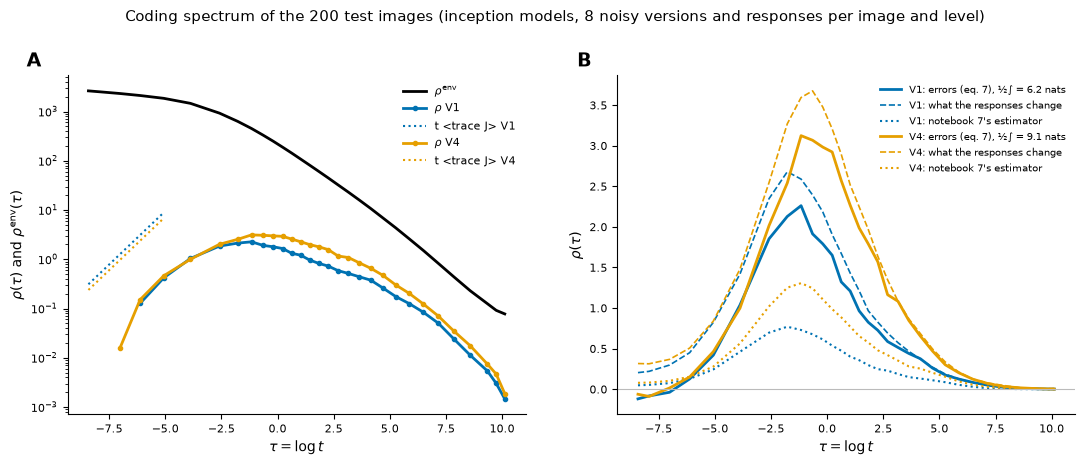

In [7]:
%%time

# 1. the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_coding_spectrum(spectra, traces, PARAMS)
fig.savefig(
    figure_dir / "coding_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 2. for each area: ½ ∫ ρ dτ in nats (and bits), both ways and for notebook 7's
# estimator; where the curve sits; levels where ρ is negative; ρ against ρ^env
for area, spectrum in spectra.items():
    log_t = spectrum.log_tau
    errors = compute_information(spectrum.env - spectrum.coded, log_t)
    gain = compute_information(spectrum.gain, log_t)
    sampled = compute_information(spectrum.sampled, log_t)
    print(
        f"{area}: ½∫ρ = {errors[0]:.2f} ± {errors[1]:.2f} nats"
        f" ({errors[0] / torch.log(torch.tensor(2.0)):.1f} bits) from the errors,"
        f" {gain[0]:.2f} ± {gain[1]:.2f} from what the responses change,"
        f" {sampled[0]:.2f} from notebook 7's estimator"
    )
    rho = spectrum.rho
    ratio = (rho / spectrum.env.mean(dim=0)).max()
    print(
        f"    centre at log t = {compute_centre(rho, log_t):.2f}; ρ < 0 at log t ="
        f" {log_t[rho < 0].numpy().round(1)}; ρ / ρ^env at most {ratio:.3f}"
    )

## 7. Conclusion

* **The coding spectrum is a bump.** For both areas, $\rho(\tau)$ rises from about zero at the finest levels, peaks at $\log t \approx -1.2$ (2.3 for V1, 3.1 for V4) and falls to about 0.002 at $\log t = 10$. It stays far below the envelope: the responses take at most 6% (V1) and 8.5% (V4) off the error of the unconditional denoiser.
* **V4 leans toward high $\log t$, V1 toward low $\log t$.** The two measured curves are the same up to $\log t \approx -2.6$; above, V4's is higher, about twice V1's from $\log t \approx 0.6$ to 3.2. V4 has 47% of its information above $\log t \approx 0$, V1 36% (centres at $\log t = -0.24$ and $-0.77$). At the fine end, the limit from the encoders alone, $t \cdot \langle \mathrm{trace}\, J(x) \rangle$, is 1.3 times higher for V1 than for V4 (mean trace 1413 against 1083): V1's responses are more sensitive to the finest details, at levels where the diffusion models do not resolve the curve (below).
* **The mutual information.** $\tfrac12 \int \rho\, d\tau$ = 6.16 ± 0.18 nats (8.9 bits) for V1 and 9.11 ± 0.23 nats (13.1 bits) for V4: the 50 neurons of V4 carry about 1.5 times more information about the image than the 50 of V1. From what the responses change, 8.15 ± 0.20 and 11.43 ± 0.22 nats (1.4 times more). The two ways give the same curve for exact posterior means; here the second is 10–30% higher around the peak, and more at finer levels, which measures how far the two branches of the networks (with the responses, and with the null token) are from exact.
* **The fine end is not resolved.** At and below $\log t \approx -6$, the measured $\rho$ is within about 0.15 of zero (negative at the 3 finest levels for V1, the 2 finest for V4), whereas the exact curve approaches $t \cdot \langle \mathrm{trace}\, J(x) \rangle$ there (0.31 for V1, 0.24 for V4 at $\log t = -8.4$, dotted in A): the errors with and without the responses (about 2600) differ by less than the precision of the networks. The integrals above miss the information carried at the finest scales; if the exact curve followed the dotted lines up to $\log t = -6$, that would be 1.8 nats more for V1 and 1.3 for V4. So "zero at both ends" holds for the measured curve; for the exact curve it holds at the coarse end, and at the fine end only as $t \to 0$.
* **Notebook 7's estimator.** The curve it measures (two responses drawn given the denoised image) is a third to a half of $\rho$ at every level from $\log t = -4$ to 6.5 (31–56%), with integrals of 2.42 (V1) and 3.93 nats (V4), about 40% of those of $\rho$: on the data, drawing the responses given $\hat x(x_t)$ instead of the image underestimates the trace of $M_t(x)$ two to three times, at all scales (in the linear-Gaussian model of the unit tests, the underestimate grew with $t$).

**Next steps**: resolve the fine end (switch to the encoders' limit $t \cdot \langle \mathrm{trace}\, J(x) \rangle$ below $\log t \approx -6$, or use a denoiser more precise at small noise); bring the two branches of the networks closer (a separately trained unconditional model, or longer training) until the two ways agree; compare the images through the integrals of their own curves (stored per image in `spectra`); and estimate the matrices $M_t(x)$ of notebook 7 the way this notebook gets what the responses change (one response given the image, against the null token), which removes the bias of drawing the responses given $\hat x(x_t)$ once averaged over the images.